# Experimento extra — modelos sem a idade

Análise complementar à etapa 6 do notebook principal (`supervised_learning.ipynb`), que não é alterado aqui. A importância por permutação mostrou que a idade domina as previsões. Este notebook responde: **o que acontece se a idade for retirada das entradas e os modelos forem retreinados?**

Protocolo: mesmos dados, mesma divisão treino/validação/teste e mesmo pré-processamento do EDA, só sem a coluna `age`. São comparadas a Regressão Logística e a MLP escolhida na etapa 4 (24-8-1, AdamW com taxa 0,003, sem regularização, viés da saída no log-odds), com e sem idade. **Tudo é avaliado apenas na validação**: o teste foi usado uma única vez, na etapa 5 do notebook principal, e continua reservado.

In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
import math, random, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
warnings.filterwarnings("ignore")
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mkdocs.yml").exists())
sys.path.insert(0, str(BASE / "docs" / "projects" / "eda" / "code"))
sys.path.insert(0, str(BASE / "docs" / "projects" / "classification" / "code"))
from preprocessing import NUM, CAT, TARGET
from mlp import treinar_mlp

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score

df = pd.read_csv(BASE / "docs" / "projects" / "eda" / "data" / "healthcare-dataset-stroke-data.csv")
X, y = df[NUM + CAT].copy(), df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)
print(f"Treino {len(X_train_sub)} · validação {len(X_val)} (teste {len(X_test)} não é usado)")


def preprocessador(numericas):
    """Mesmo pipeline do EDA (preprocessing.py), com a lista de numéricas como parâmetro."""
    num = Pipeline([("imputacao", SimpleImputer(strategy="median")), ("escala", RobustScaler())])
    return ColumnTransformer([
        ("num", num, numericas),
        ("bmi_ausente", MissingIndicator(features="all"), ["bmi"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])


VERSOES = {"com idade": NUM, "sem idade": [c for c in NUM if c != "age"]}


Treino 3270 · validação 818 (teste 1022 não é usado)


## Regressão Logística

Além da validação fixa, a Logística é avaliada por validação cruzada estratificada (5 dobras × 5 repetições) dentro do treino, para medir a variação entre divisões.

In [2]:
linhas = []
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
for nome, numericas in VERSOES.items():
    colunas = numericas + CAT
    modelo = Pipeline([("prep", preprocessador(numericas)),
                       ("clf", LogisticRegression(max_iter=1000, random_state=42))])
    modelo.fit(X_train_sub[colunas], y_train_sub)
    p = modelo.predict_proba(X_val[colunas])[:, 1]
    cv_pr = []
    for tr, va in cv.split(X_train, y_train):
        m = Pipeline([("prep", preprocessador(numericas)),
                      ("clf", LogisticRegression(max_iter=1000, random_state=42))])
        m.fit(X_train.iloc[tr][colunas], y_train.iloc[tr])
        cv_pr.append(average_precision_score(y_train.iloc[va], m.predict_proba(X_train.iloc[va][colunas])[:, 1]))
    linhas.append({"modelo": "Logística", "entradas": nome,
                   "PR-AUC validação": average_precision_score(y_val, p),
                   "ROC-AUC validação": roc_auc_score(y_val, p),
                   "PR-AUC validação cruzada (média)": np.mean(cv_pr),
                   "PR-AUC validação cruzada (desvio)": np.std(cv_pr)})
tabela_log = pd.DataFrame(linhas)
print("Tabela A — Regressão Logística com e sem idade")
display(tabela_log.round(3))


Tabela A — Regressão Logística com e sem idade


,modelo,entradas,PR-AUC validação,ROC-AUC validação,PR-AUC validação cruzada (média),PR-AUC validação cruzada (desvio)
0,Logística,com idade,0.233,0.846,0.222,0.048
1,Logística,sem idade,0.176,0.751,0.155,0.032


## MLP

A rede escolhida na etapa 4 do notebook principal, com 5 sementes. Sem a idade, a entrada passa de 24 para 23 colunas.

In [3]:
linhas = []
for nome, numericas in VERSOES.items():
    colunas = numericas + CAT
    prep = preprocessador(numericas)
    A = torch.tensor(prep.fit_transform(X_train_sub[colunas]), dtype=torch.float32)
    B = torch.tensor(prep.transform(X_val[colunas]), dtype=torch.float32)
    C = torch.tensor(y_train_sub.to_numpy(), dtype=torch.float32)
    D = torch.tensor(y_val.to_numpy(), dtype=torch.float32)
    prev = float(y_train_sub.mean())
    for s in range(5):
        _, r = treinar_mlp(A, C, B, D, s, lr=0.003, vies_saida=math.log(prev / (1 - prev)))
        linhas.append({"entradas": nome, "colunas de entrada": A.shape[1], "semente": s,
                       "PR-AUC validação": r["PR-AUC validação"], "melhor época": r["melhor época"]})
det_mlp = pd.DataFrame(linhas)
tabela_mlp = det_mlp.groupby("entradas").agg(
    **{"colunas de entrada": ("colunas de entrada", "first"),
       "PR-AUC média": ("PR-AUC validação", "mean"),
       "desvio": ("PR-AUC validação", "std"),
       "melhor época média": ("melhor época", "mean")}).reindex(["com idade", "sem idade"])
print("Tabela B — MLP com e sem idade (validação, 5 sementes)")
display(tabela_mlp.round(3))


Tabela B — MLP com e sem idade (validação, 5 sementes)


,colunas de entrada,PR-AUC média,desvio,melhor época média
entradas,,,,
com idade,24,0.228,0.010,9.2
sem idade,23,0.169,0.008,7.6


## Para onde vai o sinal sem a idade?

Coeficientes da Logística sem idade, em comparação com a versão com idade: indicam quais variáveis passam a carregar a informação que a idade levava. Como as numéricas estão na mesma escala robusta e as categóricas são 0/1, os coeficientes são comparáveis dentro de cada grupo.

In [4]:
coefs = {}
for nome, numericas in VERSOES.items():
    colunas = numericas + CAT
    m = Pipeline([("prep", preprocessador(numericas)),
                  ("clf", LogisticRegression(max_iter=1000, random_state=42))]).fit(X_train_sub[colunas], y_train_sub)
    nomes = [n.split("__", 1)[1] for n in m["prep"].get_feature_names_out()]
    coefs[nome] = pd.Series(m["clf"].coef_[0], index=nomes)
tabela_coef = pd.DataFrame(coefs)
tabela_coef["mudança"] = tabela_coef["sem idade"] - tabela_coef["com idade"]
tabela_coef = tabela_coef.reindex(tabela_coef["mudança"].abs().sort_values(ascending=False).index)
print("Tabela C — Coeficientes da Logística (ordenados pela mudança ao retirar a idade)")
display(tabela_coef.round(3).head(12))


Tabela C — Coeficientes da Logística (ordenados pela mudança ao retirar a idade)


,com idade,sem idade,mudança
work_type_children,0.294,-1.068,-1.362
work_type_Self-employed,-0.214,0.619,0.834
ever_married_No,0.113,-0.347,-0.460
work_type_Govt_job,-0.080,0.339,0.419
ever_married_Yes,-0.107,0.275,0.381
heart_disease_0,-0.067,-0.436,-0.369
work_type_Private,0.053,0.353,0.300
heart_disease_1,0.074,0.364,0.290
work_type_Never_worked,-0.046,-0.316,-0.269
hypertension_0,-0.145,-0.389,-0.244


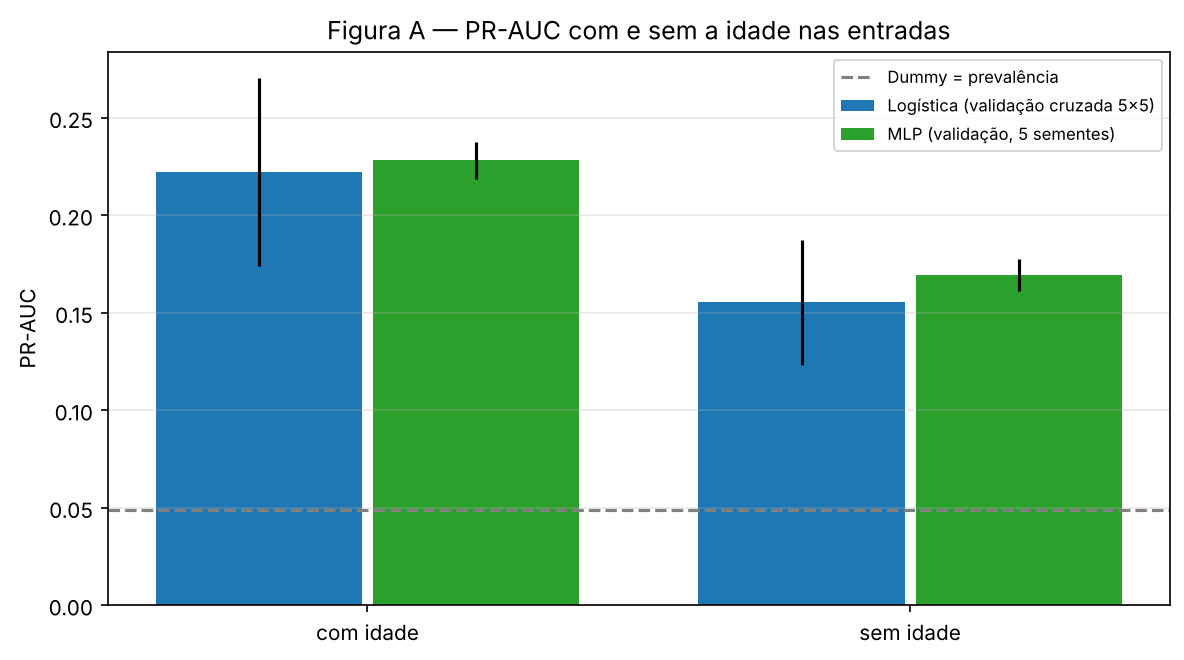

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
try:
    grupos = ["com idade", "sem idade"]
    x = np.arange(2)
    log_v = tabela_log.set_index("entradas").loc[grupos]
    ax.bar(x - 0.2, log_v["PR-AUC validação cruzada (média)"], 0.38,
           yerr=log_v["PR-AUC validação cruzada (desvio)"], color="tab:blue", label="Logística (validação cruzada 5×5)")
    ax.bar(x + 0.2, tabela_mlp.loc[grupos, "PR-AUC média"], 0.38,
           yerr=tabela_mlp.loc[grupos, "desvio"], color="tab:green", label="MLP (validação, 5 sementes)")
    ax.axhline(float(y_val.mean()), color="gray", linestyle="--", label="Dummy = prevalência")
    ax.set_xticks(x, grupos)
    ax.set(ylabel="PR-AUC", title="Figura A — PR-AUC com e sem a idade nas entradas")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    with BytesIO() as buf:
        fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
        display(Image(data=buf.getvalue(), format="png"))
finally:
    plt.close(fig)


## Leitura

**Sem a idade, os dois modelos perdem cerca de um quarto da PR-AUC.** A Logística cai de 0,233 para 0,176 na validação (de 0,222 para 0,155 na validação cruzada) e a ROC-AUC, de 0,846 para 0,751. A MLP cai de 0,228 ± 0,010 para 0,169 ± 0,008. A queda é grande, maior que o ruído entre sementes e entre divisões, o que confirma que a idade é a variável mais informativa do dataset.

**A queda é menor que a da permutação.** Embaralhar a idade no modelo treinado derrubava a PR-AUC em ≈ 0,14 (etapa 6); retirá-la e retreinar derruba em ≈ 0,06. A diferença vem da redistribuição do sinal: sem a idade, o modelo passa a usar as variáveis que carregam parte dessa informação. A Tabela C mostra isso na Logística: `work_type_children` passa a ter o maior coeficiente negativo (crianças quase não têm AVC), e estado civil, doença cardíaca e hipertensão ganham peso, todas associadas à idade, como o EDA apontou (Tabela 6A, possível confundimento).

**Sem a idade, a rede continua empatada com a Logística** (0,169 contra 0,176). Mesmo com uma variável a menos e o problema mais difícil, a camada oculta não encontra padrões que um modelo linear não encontre. O resultado reforça a conclusão do notebook principal: o limite está na informação das variáveis, não na capacidade do modelo.

Os dois modelos sem idade ainda ficam bem acima do Dummy (0,049): glicose, comorbidades e as variáveis associadas à idade carregam sinal próprio.

*Este experimento usou só a validação; nenhuma escolha do notebook principal foi alterada por ele.*
